# Laboratorio 4 — Módulo 4, Sesión 5 · Cuaderno del participante
## De cuaderno a script, programar tareas y flujos ETL

**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN · DC.2026.V1.896**
**Banco Central del Ecuador · Lunes 26 de octubre de 2026 · 18:30 a 21:30**
Ing. Jonathan E. Tito O., MSc.

---

**Numerales de hoy:** **3.1** Scripts automatizados · **3.2** Programación de tareas · **3.3** Flujos ETL · **5.3** Automatización analítica *(formativa, 10 puntos)*. **Empieza la unidad 3.**

## El mapa de las tres horas

| | Qué | Min |
|---|---|---|
| § 0 | Preparar el entorno | 5 |
| § 1 | **3.1** El flujo, abierto y leído | 20 |
| § 2 | **3.1** Práctica: tres modificaciones | 15 |
| | **Descanso** | 10 |
| § 3 | **3.2** Programar: nadie está mirando | 20 |
| § 4 | **3.3** Flujo ETL completo: tres ejercicios | 30 |
| | **Descanso** | 10 |
| § 5 | **5.3** Taller en salas · **10 puntos** | 40 |
| § 6 | Cierre y entregas | 10 |

---

<div style="background:#E8F4F3;border-left:6px solid #168A88;padding:12px 16px;margin:8px 0;border-radius:4px"><b style="color:#168A88">Cómo se usa este cuaderno</b><br>Este cuaderno es <b>autónomo</b>: crea por sí mismo el script y los datos de la clase, así que no necesita el kit. Si prefiere trabajar con el kit (<code>M4_S5_KIT.zip</code>), también sirve: cada archivo se crea solo si no existe.<br><br>Las celdas <b>[COMPLETE]</b> están incompletas a propósito: los huecos son <code>___</code>. Los datos son <b>sintéticos</b>: no son del BCE ni del INEC.<br><br><b>Plan B:</b> si falla Colab, un integrante comparte pantalla y los demás siguen en papel; el script completo está en el chat.</div>

## § 0 · Preparar el entorno *(5 min)*

Las celdas de abajo hacen tres cosas: ven qué hora cree esta máquina que es, crean la carpeta de datos con los dos archivos de la clase, y definen una función auxiliar llamada `ejecutar` que usaremos para **probar el script sin dañar el original**.

In [11]:
# Celda 0.1 — la hora que cree esta maquina.
# "!" le pasa una orden a la terminal. "date" imprime la fecha y la hora del sistema.
# Compare con su reloj: si hay 5 horas de diferencia, esta maquina trabaja en UTC.
!date

Wed Oct 28 01:18:36 UTC 2026


In [12]:
# Celda 0.2 — herramientas y carpetas.
import os, sys, shutil, subprocess, logging
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("datos", exist_ok=True)
os.makedirs("salida", exist_ok=True)
print("carpeta de trabajo:", os.getcwd())

carpeta de trabajo: /workspaces/m4-bd-ia-bce


In [13]:
# Celda 0.3 — los dos archivos de datos de la clase (SINTETICOS).
# Cada archivo se crea solo si no existe, para no pisar el del kit si usted lo subio.
EXPORTACIONES = """producto,monto_mm_usd
Banano y plátano,1252.41
Camarón,3253.37
Cacao y elaborados,966.35
Petróleo crudo,2588.27
Flores naturales,387.11
Atún y pescado,231.62
"""
CATALOGO = """producto,codigo
Banano y plátano,0803
Camarón,0306
CACAO Y ELABORADOS,1801
Petróleo crudo,2709
Flores naturales,0603
Café,0901
"""
for ruta, texto in [("datos/exportaciones.csv", EXPORTACIONES), ("datos/catalogo.csv", CATALOGO)]:
    if not Path(ruta).exists():
        Path(ruta).write_text(texto, encoding="utf-8")
        print("creado :", ruta)
    else:
        print("ya existe:", ruta)
print(pd.read_csv("datos/exportaciones.csv"))

ya existe: datos/exportaciones.csv
ya existe: datos/catalogo.csv
             producto  monto_mm_usd
0    Banano y plátano       1252.41
1             Camarón       3253.37
2  Cacao y elaborados        966.35
3      Petróleo crudo       2588.27
4    Flores naturales        387.11


In [14]:
# Celda 0.4 — la funcion auxiliar "ejecutar".
# PROBLEMA: para ver como falla el script hay que danarlo a proposito (cambiar un parametro, borrar una
# fila). Si lo hacemos sobre el original, despues hay que acordarse de devolverlo.
# SOLUCION: esta funcion hace una COPIA de trabajo en la carpeta "_ensayo", aplica ahi los cambios,
# corre la copia, muestra el codigo de salida y anota el registro en el flujo.log real.
#   cambios_script : {texto_viejo: texto_nuevo} sobre el script
#   cambios_datos  : {archivo: (texto_viejo, texto_nuevo)} sobre los CSV
def ejecutar(script="flujo_exportaciones.py", cambios_script=None, cambios_datos=None):
    carpeta = Path("_ensayo")
    shutil.rmtree(carpeta, ignore_errors=True)
    shutil.copytree("datos", carpeta / "datos")
    texto = Path(script).read_text(encoding="utf-8")
    for viejo, nuevo in (cambios_script or {}).items():
        if viejo not in texto:
            print("AVISO: no encontre este texto en el script:", repr(viejo)); return
        texto = texto.replace(viejo, nuevo)
    (carpeta / script).write_text(texto, encoding="utf-8")
    for archivo, (viejo, nuevo) in (cambios_datos or {}).items():
        contenido = (carpeta / archivo).read_text(encoding="utf-8")
        if viejo not in contenido:
            print("AVISO: no encontre este texto en", archivo, ":", repr(viejo)); return
        (carpeta / archivo).write_text(contenido.replace(viejo, nuevo), encoding="utf-8")
    r = subprocess.run([sys.executable, script], cwd=carpeta, capture_output=True, text=True)
    print((r.stdout + r.stderr).strip())
    print(">>> CODIGO DE SALIDA:", r.returncode, "(0 = bien, otro numero = fallo)")
    registro = carpeta / "flujo.log"
    if registro.exists():
        with open("flujo.log", "a", encoding="utf-8") as f:
            f.write(registro.read_text(encoding="utf-8"))
    return r.returncode
print("lista: ejecutar(...)")

lista: ejecutar(...)


<div style="background:#FDEDEC;border-left:6px solid #DE1E1B;padding:12px 16px;margin:8px 0;border-radius:4px"><b style="color:#DE1E1B">El problema</b><br>Un cuaderno necesita <b>una persona que haga clic</b> en cada celda, en orden, y guarda estado oculto: una variable creada en la celda 4 puede estar cambiando el resultado de la celda 20, y nadie lo ve. No se puede dejar corriendo solo.</div>

<div style="background:#EAF0F6;border-left:6px solid #092240;padding:12px 16px;margin:8px 0;border-radius:4px"><b style="color:#092240">Definición</b><br><b>Un script es un archivo de texto con instrucciones de Python que se ejecuta de arriba abajo con un solo comando.</b></div>

## § 1 · El flujo, abierto y leído *(20 min · numeral 3.1)*

**Ejemplo mínimo.** Un archivo `hola.py` con la línea `print("hola")` se corre escribiendo `python hola.py`.

McKinney lo dice así: *«el script se ejecuta en un espacio de nombres vacío… de modo que el comportamiento debe ser idéntico a la ejecución del programa en la línea de comandos utilizando `python script.py`»* [L3: El comando %run]. Empieza **vacío**, sin variables heredadas. Eso lo hace **reproducible**.

**Tres zonas, siempre en este orden:** (1) **parámetros** arriba, todo lo que puede cambiar; (2) **funciones**, una por paso; (3) **la lógica**, abajo, dentro de `if __name__ == "__main__":`, que es **la puerta de entrada**: lo que está debajo corre solo cuando el archivo se ejecuta directamente.

La celda siguiente **crea el archivo** `flujo_exportaciones.py`. No lo ejecuta: **primero se lee, de arriba abajo.**

In [15]:
%%writefile flujo_exportaciones.py
"""Flujo de exportaciones: extrae dos fuentes, las une con defensas y guarda el resultado.
Autor: J. Tito · Creado: 2026-10-26 · Fuente: datos de clase (sinteticos)"""
import logging, sys, unicodedata
from datetime import date
import pandas as pd

# ---------- 1 · PARAMETROS (todo lo que puede cambiar, junto y arriba) ----------
RUTA_EXPORTACIONES = "datos/exportaciones.csv"
RUTA_CATALOGO      = "datos/catalogo.csv"
SALIDA             = f"salida/exportaciones_con_codigo_{date.today().isoformat()}.csv"
FILAS_ESPERADAS    = 6
TOTAL_ESPERADO     = 8679.13

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s",
                    handlers=[logging.FileHandler("flujo.log"), logging.StreamHandler()])
log = logging.getLogger("flujo")

# ---------- 2 · LAS TRES FUNCIONES ----------
def normalizar(texto):
    sin_tildes = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()
    return sin_tildes.strip().lower()

def extraer():
    a = pd.read_csv(RUTA_EXPORTACIONES); b = pd.read_csv(RUTA_CATALOGO, dtype={"codigo": str})
    log.info("extraidas %d filas de exportaciones y %d del catalogo", len(a), len(b))
    return a, b

def transformar(a, b):
    a["clave"] = a["producto"].map(normalizar); b["clave"] = b["producto"].map(normalizar)
    if len(a) != FILAS_ESPERADAS:
        raise ValueError(f"esperaba {FILAS_ESPERADAS} filas y llegaron {len(a)}")
    union = pd.merge(a, b[["clave", "codigo"]], on="clave", how="left",
                     validate="one_to_one", indicator=True)
    sin_cruzar = union[union["_merge"] != "both"]
    if len(sin_cruzar):
        log.warning("%d filas sin codigo: %s", len(sin_cruzar), list(sin_cruzar["producto"]))
    total = round(union["monto_mm_usd"].sum(), 2)
    if abs(total - TOTAL_ESPERADO) > 0.01:
        raise ValueError(f"el total cambio: esperaba {TOTAL_ESPERADO} y salio {total}")
    return union.drop(columns=["clave", "_merge"])

def cargar(tabla):
    import os; os.makedirs("salida", exist_ok=True)
    tabla.to_csv(SALIDA, index=False); log.info("guardado %s (%d filas)", SALIDA, len(tabla))

# ---------- 3 · LA LOGICA, EN ORDEN ----------
if __name__ == "__main__":
    try:
        a, b = extraer(); cargar(transformar(a, b)); log.info("FIN OK")
    except Exception as error:
        log.error("EL FLUJO FALLO: %s", error); sys.exit(1)

Overwriting flujo_exportaciones.py


**Lo nuevo respecto del viernes**

- **`normalizar`** resuelve `CAMARON` contra `Camarón`: quita tildes y pasa a minúsculas **antes** de unir. Normalizar es una decisión de dominio; acá se toma y queda escrita.
- **`validate="one_to_one"` e `indicator=True`** son las dos defensas de la sesión 4, ahora dentro de una función.
- **`log.warning` para lo que no cruza, `raise` para lo que no puede seguir.** Una fila sin código es una advertencia; un total distinto es un fallo.

In [16]:
# Celda 1.2 — corre el flujo COMO SCRIPT, con un solo comando, y muestra el codigo de salida.
# "echo $?" imprime el numero con que termino el programa anterior: 0 = salio bien.
!python flujo_exportaciones.py; echo "CODIGO DE SALIDA: $?"

2026-10-28 01:19:12,975 INFO extraidas 5 filas de exportaciones y 6 del catalogo
2026-10-28 01:19:12,977 ERROR EL FLUJO FALLO: esperaba 6 filas y llegaron 5
CODIGO DE SALIDA: 1


In [17]:
# Celda 1.3 — el registro que dejo. Cada linea: hora, nivel de gravedad, mensaje.
!cat flujo.log

2026-10-27 02:12:56,689 INFO extraidas 6 filas de exportaciones y 6 del catalogo
2026-10-27 02:12:56,715 WARNING 1 filas sin codigo: ['Atún y pescado']
2026-10-27 02:12:56,717 INFO guardado salida/exportaciones_con_codigo_2026-10-27.csv (6 filas)
2026-10-27 02:12:56,718 INFO FIN OK
2026-10-28 01:01:57,563 INFO extraidas 6 filas de exportaciones y 6 del catalogo
2026-10-28 01:01:57,590 WARNING 1 filas sin codigo: ['Atún y pescado']
2026-10-28 01:01:57,593 INFO guardado salida/exportaciones_con_codigo_2026-10-28.csv (6 filas)
2026-10-28 01:01:57,593 INFO FIN OK
2026-10-28 01:15:08,392 INFO extraidas 5 filas de exportaciones y 6 del catalogo
2026-10-28 01:15:08,396 ERROR EL FLUJO FALLO: esperaba 6 filas y llegaron 5
2026-10-28 01:19:12,975 INFO extraidas 5 filas de exportaciones y 6 del catalogo
2026-10-28 01:19:12,977 ERROR EL FLUJO FALLO: esperaba 6 filas y llegaron 5


<div style="background:#EAF6EF;border-left:6px solid #1B7F4B;padding:12px 16px;margin:8px 0;border-radius:4px"><b style="color:#1B7F4B">Lo que acaba de pasar</b><br>El programa <b>no le preguntó nada a nadie</b>. Y dejó dicho qué hizo, a qué hora, y qué le llamó la atención (la fila de <i>Atún y pescado</i> no tiene código en el catálogo).</div>

<div style="background:#EAF0F6;border-left:6px solid #092240;padding:12px 16px;margin:8px 0;border-radius:4px"><b style="color:#092240">Registro (log) · niveles</b><br><b>Un registro es un archivo donde el programa anota qué hizo y cuándo, con un nivel de gravedad.</b> Un <code>print</code> existe solo mientras alguien mira la pantalla; un proceso que corre a las 07:00 sin nadie delante no tiene a quién imprimirle.<br><br><code>INFO</code> (20): pasó lo esperado · <code>WARNING</code> (30): algo raro, pero siguió · <code>ERROR</code> (40): falló y se detuvo.<br>Existen también <code>DEBUG</code> (10) y <code>CRITICAL</code> (50).</div>

<div style="background:#EAF0F6;border-left:6px solid #092240;padding:12px 16px;margin:8px 0;border-radius:4px"><b style="color:#092240">Código de salida</b><br><b>Es un número que el programa entrega al terminar: 0 es que todo salió bien, cualquier otro es que falló.</b> Si un script falla y simplemente termina, el sistema que lo lanzó no se entera. A mano no sirve de nada; sirve cuando <b>otro programa</b> lanza el flujo y necesita saber si debe avisar.</div>

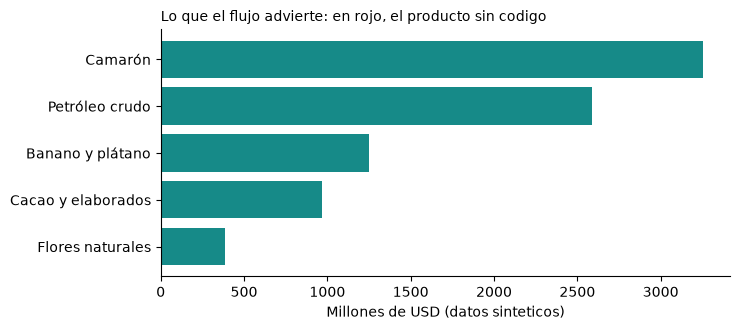

In [18]:
# Celda 1.4 — grafico: que filas cruzaron con el catalogo y cuales no.
exp = pd.read_csv("datos/exportaciones.csv")
cat = pd.read_csv("datos/catalogo.csv", dtype={"codigo": str})
import unicodedata
norm = lambda t: unicodedata.normalize("NFKD", t).encode("ascii", "ignore").decode().strip().lower()
exp["cruza"] = exp["producto"].map(norm).isin(cat["producto"].map(norm))
exp = exp.sort_values("monto_mm_usd")
colores = ["#168A88" if c else "#DE1E1B" for c in exp["cruza"]]
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.barh(exp["producto"], exp["monto_mm_usd"], color=colores)
ax.set_xlabel("Millones de USD (datos sinteticos)")
ax.set_title("Lo que el flujo advierte: en rojo, el producto sin codigo", loc="left", fontsize=10)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

## § 2 · Práctica: tres modificaciones *(15 min · numeral 3.1)*

La función `ejecutar` trabaja sobre una **copia**: el original no se daña. Complete los huecos `___` y corra cada celda. **Escriba en el chat lo que dice el registro y qué número aparece al final.**

**Modificación 1 · cambiar un parámetro.** Ponga `FILAS_ESPERADAS = 7`.

In [19]:
# [COMPLETE] Modificacion 1 — FILAS_ESPERADAS: de 6 a ___
# ejecutar(cambios_script={"FILAS_ESPERADAS    = 6": "FILAS_ESPERADAS    = 7"})

**Modificación 2 · romper la fuente a propósito.** Borre la última línea de `datos/exportaciones.csv` (la de *Atún y pescado*). ¿Qué se rompe primero?

In [20]:
# [COMPLETE] Modificacion 2 — borrar la ultima fila del CSV de exportaciones.
# Pista: el texto a reemplazar es la fila entera, con su salto de linea, y el reemplazo es "" (nada).
# ejecutar(cambios_datos={"datos/exportaciones.csv": ("Atún y pescado,231.62\n", ___)})

**Modificación 3 · el dato llega, pero cambiado.** Deje el archivo completo y cambie un monto: `1252.41` por `1252.14`. **No toque ningún parámetro.**

In [ ]:
# [COMPLETE] Modificacion 3 — cambiar un monto (dos digitos intercambiados).
# ejecutar(cambios_datos={"datos/exportaciones.csv": ("1252.41", "___")})

2026-10-27 01:06:14,896 INFO extraidas 6 filas de exportaciones y 6 del catalogo
2026-10-27 01:06:14,908 WARNING 1 filas sin codigo: ['Atún y pescado']
2026-10-27 01:06:14,913 ERROR EL FLUJO FALLO: type str doesn't define __round__ method
>>> CODIGO DE SALIDA: 1 (0 = bien, otro numero = fallo)


1

<div style="background:#FDF6E3;border-left:6px solid #B57C20;padding:12px 16px;margin:8px 0;border-radius:4px"><b style="color:#B57C20">Ojo</b><br><b>Un proceso sin comprobaciones no es automático: es ciego.</b> La modificación 3 es el caso que más importa: las filas están bien, el archivo abre, y la cifra está mal. Sin la comprobación del total, nadie se entera.</div>

<div style="background:#FDEDEC;border-left:6px solid #DE1E1B;padding:12px 16px;margin:8px 0;border-radius:4px"><b style="color:#DE1E1B">El problema</b><br><b>Con alguien mirando</b>, un error aparece en pantalla. <b>Sin nadie</b>, un error no lo ve nadie, y una fuente caída produce un archivo viejo o vacío. Por eso se enseñaron antes registro y código de salida: programar sin ellos es la forma más eficiente de equivocarse a escala.</div>

<div style="background:#EAF0F6;border-left:6px solid #092240;padding:12px 16px;margin:8px 0;border-radius:4px"><b style="color:#092240">Definición</b><br><b>Programar una tarea es dejar escrito <i>cuándo</i> debe correr un script, para que lo lance la máquina y no una persona.</b></div>

## § 3 · Programar: nadie está mirando *(20 min · numeral 3.2)*

Abajo está el **programador de demostración**. Se lee **antes** de correrlo. Qué hace cada línea:

- `subprocess.run` **lanza otro programa**, como si lo escribiéramos en la terminal. Eso es lo que hace un programador de tareas.
- `r.returncode` **lee el código de salida** del flujo.
- `schedule.every(20).seconds.do(correr)` es la programación: *«cada 20 segundos, corra esta función»*.
- El `while` revisa **cada segundo** si le toca algo, y se **detiene solo a los 70 segundos**, para no dejar la celda tomada.

In [ ]:
# !pip install schedule

In [23]:
# Celda 3.0 — la biblioteca "schedule" NO viene preinstalada en Colab.
# Si la importacion falla, esta celda la instala UNA vez (necesita red). Si su red la bloquea,
# diga "sin schedule" en el chat: la demostracion la hace el docente en pantalla (Plan B).
try:
    import schedule
    from importlib.metadata import version
    print("schedule ya esta disponible, version", version("schedule"))
except ImportError:
    # Para evitar instalar sin querer, la linea siguiente va comentada: quite el "#" y corra la celda.
    # !pip install -q schedule
    print("schedule NO esta instalada: quite el # de la linea de arriba y corra de nuevo")

schedule ya esta disponible, version 1.2.2


La celda siguiente crea `prog.py`. (Su primera línea, `%%writefile`, no es Python: es una orden del cuaderno que guarda lo de abajo en un archivo.)

In [24]:
%%writefile prog.py
import schedule, time, subprocess, sys, logging
logging.basicConfig(level=logging.INFO, format="%(asctime)s %(message)s")

INTERVALO_SEG = 20      # en clase: cada 20 segundos. En real seria: schedule.every().day.at("12:00")
DURACION_SEG  = 70      # el programa se detiene solo, para no dejar la celda o la terminal tomada

def correr():
    r = subprocess.run([sys.executable, "flujo_exportaciones.py"], capture_output=True, text=True)
    logging.info("el flujo termino con codigo %d", r.returncode)

schedule.every(INTERVALO_SEG).seconds.do(correr)
fin = time.time() + DURACION_SEG
while time.time() < fin:
    schedule.run_pending()
    time.sleep(1)
logging.info("programador detenido")

Overwriting prog.py


In [25]:
# Celda 3.2 — corre el programador. Dura 70 segundos y se detiene solo.
# Mientras corre: la notacion cron (solo para RECONOCERLA, no se evalua).
#   cinco campos:  minuto  hora  dia-del-mes  mes  dia-de-la-semana
#   "0 12 * * 1-5"  =  a las 12:00, cualquier dia del mes, cualquier mes, de lunes a viernes. El * es "cualquiera".
!python prog.py

2026-10-28 01:25:10,073 el flujo termino con codigo 1
2026-10-28 01:25:30,602 el flujo termino con codigo 1
2026-10-28 01:25:51,158 el flujo termino con codigo 1
2026-10-28 01:26:00,159 programador detenido


In [26]:
# Celda 3.3 — el registro: tres corridas seguidas, con su hora, que nadie lanzo.
!tail -n 12 flujo.log

2026-10-28 01:01:57,593 INFO guardado salida/exportaciones_con_codigo_2026-10-28.csv (6 filas)
2026-10-28 01:01:57,593 INFO FIN OK
2026-10-28 01:15:08,392 INFO extraidas 5 filas de exportaciones y 6 del catalogo
2026-10-28 01:15:08,396 ERROR EL FLUJO FALLO: esperaba 6 filas y llegaron 5
2026-10-28 01:19:12,975 INFO extraidas 5 filas de exportaciones y 6 del catalogo
2026-10-28 01:19:12,977 ERROR EL FLUJO FALLO: esperaba 6 filas y llegaron 5
2026-10-28 01:25:10,011 INFO extraidas 5 filas de exportaciones y 6 del catalogo
2026-10-28 01:25:10,013 ERROR EL FLUJO FALLO: esperaba 6 filas y llegaron 5
2026-10-28 01:25:30,539 INFO extraidas 5 filas de exportaciones y 6 del catalogo
2026-10-28 01:25:30,542 ERROR EL FLUJO FALLO: esperaba 6 filas y llegaron 5
2026-10-28 01:25:51,107 INFO extraidas 5 filas de exportaciones y 6 del catalogo
2026-10-28 01:25:51,109 ERROR EL FLUJO FALLO: esperaba 6 filas y llegaron 5


**Ahora, romperlo delante de todos.** La celda siguiente cambia `FILAS_ESPERADAS` a 7 **en el archivo real**, y la que sigue lo devuelve. Entre las dos, se corre `prog.py` otra vez. Mientras corre: la hora.

In [27]:
# Celda 3.4 — ROMPER el flujo real (FILAS_ESPERADAS = 7).
t = Path("flujo_exportaciones.py").read_text(encoding="utf-8")
assert "FILAS_ESPERADAS    = 6" in t, "el script ya esta modificado o no tiene el formato esperado"
Path("flujo_exportaciones.py").write_text(t.replace("FILAS_ESPERADAS    = 6", "FILAS_ESPERADAS    = 7"), encoding="utf-8")
print("flujo ROTO a proposito: FILAS_ESPERADAS = 7")

flujo ROTO a proposito: FILAS_ESPERADAS = 7


In [28]:
# Celda 3.5 — correr el programador con el flujo roto (70 segundos).
# Mientras corre (esta celda queda ocupada), espere: ¿cuantas veces cree que fallara en 70 segundos?
!python prog.py

2026-10-28 01:26:46,277 el flujo termino con codigo 1
2026-10-28 01:27:06,750 el flujo termino con codigo 1
2026-10-28 01:27:27,487 el flujo termino con codigo 1
2026-10-28 01:27:36,488 programador detenido


In [29]:
# Celda 3.6 — DEVOLVER el flujo a su estado correcto. No siga sin correr esta celda.
t = Path("flujo_exportaciones.py").read_text(encoding="utf-8")
Path("flujo_exportaciones.py").write_text(t.replace("FILAS_ESPERADAS    = 7", "FILAS_ESPERADAS    = 6"), encoding="utf-8")
print("restaurado: FILAS_ESPERADAS = 6")
!python flujo_exportaciones.py; echo "CODIGO DE SALIDA: $?"

restaurado: FILAS_ESPERADAS = 6
2026-10-28 01:27:48,350 INFO extraidas 5 filas de exportaciones y 6 del catalogo
2026-10-28 01:27:48,352 ERROR EL FLUJO FALLO: esperaba 6 filas y llegaron 5
CODIGO DE SALIDA: 1


{'INFO': 15, 'WARNING': 2, 'ERROR': 9}


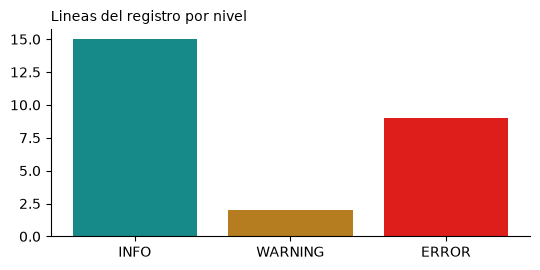

In [30]:
# Celda 3.7 — el registro cuenta lo que paso. El programador siguio corriendo; el flujo fallo; y lo unico
# que lo dice es una linea en un archivo.
import re, collections
niveles = collections.Counter(re.findall(r" (INFO|WARNING|ERROR) ", Path("flujo.log").read_text(encoding="utf-8")))
print(dict(niveles))
fig, ax = plt.subplots(figsize=(5.5, 2.8))
ax.bar(list(niveles.keys()), list(niveles.values()),
       color=[{"INFO": "#168A88", "WARNING": "#B57C20", "ERROR": "#DE1E1B"}[k] for k in niveles])
ax.set_title("Lineas del registro por nivel", loc="left", fontsize=10)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

<div style="background:#FDEDEC;border-left:6px solid #DE1E1B;padding:12px 16px;margin:8px 0;border-radius:4px"><b style="color:#DE1E1B">La pregunta</b><br><b>El flujo falló tres veces. ¿Quién se enteró?</b> Nadie, hasta que alguien abra el archivo. Esto queda abierto a propósito: mañana, en 3.5, se cierra con un control que detiene el proceso con ruido.</div>

### Tres trampas del programador

**1 · La hora.** Muchos servicios trabajan en UTC. Quito está 5 horas por detrás y no cambia de hora: **las 07:00 de Quito son las 12:00 UTC.** La biblioteca `schedule` usa la hora que *cree la máquina*. Se comprueba con `date`, no se supone.

**2 · El Codespace se apaga.** *«Por omisión, un codespace se detiene tras 30 minutos de inactividad»* y *«cuando se detiene un codespace, todos los procesos en ejecución se detienen»* [Documentación de GitHub: *Understanding the codespace lifecycle*, consultada el 25-10-2026]. Lo de recién es una demostración, no un servicio.

**3 · Un servicio externo** (GitHub Actions): *«por omisión, los flujos programados corren en UTC»*, el intervalo mínimo es **cada 5 minutos**, el evento *«puede demorarse en periodos de alta carga»* y *«en un repositorio público, los flujos programados se desactivan solos cuando no ha habido actividad en 60 días»* [Documentación de GitHub: *Events that trigger workflows*, evento `schedule`, consultada el 25-10-2026].

**Qué usar de verdad** depende de dónde viva su proceso y de lo que su área de sistemas permita en esos equipos. El *Programador de tareas* de Windows puede estar restringido por política del equipo.

<div style="background:#FDF6E3;border-left:6px solid #B57C20;padding:12px 16px;margin:8px 0;border-radius:4px"><b style="color:#B57C20">Malentendido típico</b><br><i>«Si lo programo, funciona.»</i> Programarlo es solo la mitad: la otra mitad es <b>saber que corrió</b>.</div>

30 min cada mes                    se paga en   6.0 meses
4 h cada trimestre                 se paga en   4.5 meses
1 semana al mes (supuesto 40 h)    se paga en   0.5 meses


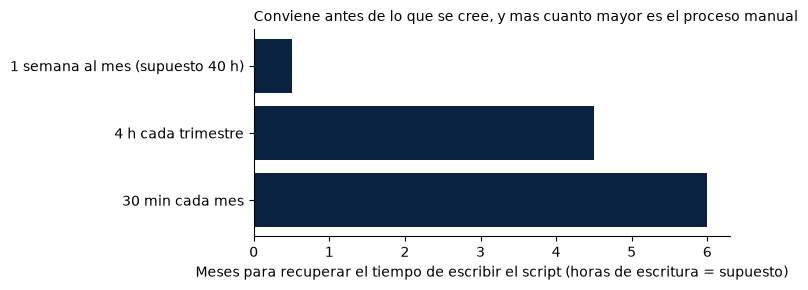

Lo caro no es escribirlo: es MANTENERLO cuando la fuente cambia de formato.


In [31]:
# Celda 3.8 — ¿cuando conviene automatizar? Se paga en (horas de escribir el script) / (horas por mes que ahorra).
# Los tres tiempos MANUALES son los que ustedes declararon en la diagnostica.
# Las horas de ESCRITURA del script y las 40 h de "una semana" son SUPUESTOS para ilustrar, NO son datos.
procesos = {"30 min cada mes":                (0.5,   3),
            "4 h cada trimestre":             (4/3,   6),
            "1 semana al mes (supuesto 40 h)": (40,   20)}
nombres = list(procesos); meses = [esc/hmes for hmes, esc in procesos.values()]
for n, m in zip(nombres, meses): print(f"{n:34s} se paga en {m:5.1f} meses")
fig, ax = plt.subplots(figsize=(7.5, 3))
ax.barh(nombres, meses, color="#092240")
ax.set_xlabel("Meses para recuperar el tiempo de escribir el script (horas de escritura = supuesto)")
ax.set_title("Conviene antes de lo que se cree, y mas cuanto mayor es el proceso manual", loc="left", fontsize=10)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()
print("Lo caro no es escribirlo: es MANTENERLO cuando la fuente cambia de formato.")

## § 4 · Flujo ETL completo: tres ejercicios *(30 min · numeral 3.3)*

**ETL = Extraer, Transformar, Cargar**: traer los datos, arreglarlos y validarlos, y guardarlos. Erl, Khattak y Buhler, Big Data Fundamentals: Concepts, Drivers & Techniques lo describe en un caso: *«el EDW (Enterprise Data Warehouse: el almacén central de datos de una organización.) se alimenta semanalmente mediante múltiples operaciones ETL que implican extraer datos de las tablas… validar y transformar los datos, y cargarlos en la base de datos del EDW»* [L6: Parte I, caso de estudio ETI]. **EDW** es el almacén central de datos de una organización. Nótese que **la validación vive dentro de la transformación**.

Lo nuevo de hoy no es el concepto: es que **cada letra es una función y las tres se corren con un comando.**

**Ejercicio 1 · el nombre del archivo lleva la fecha.** `SALIDA` usa `date.today()`. Corra el flujo y abra la carpeta `salida/`. ¿Por qué esto es trazabilidad?

In [32]:
# Ejercicio 1 — corra el flujo y liste la carpeta de salida.
!python flujo_exportaciones.py; echo "CODIGO DE SALIDA: $?"
!ls -l salida/
# Respuesta para el chat: cada corrida deja su propio archivo y no pisa el anterior (si es otro dia).
# Nota: dos corridas el MISMO dia generan el mismo nombre y la segunda sobrescribe. Con la hora en el nombre, habria uno por corrida.

2026-10-28 01:28:27,541 INFO extraidas 5 filas de exportaciones y 6 del catalogo
2026-10-28 01:28:27,544 ERROR EL FLUJO FALLO: esperaba 6 filas y llegaron 5
CODIGO DE SALIDA: 1
total 8
-rw-rw-rw- 1 jovyan users 195 Oct 27 02:12 exportaciones_con_codigo_2026-10-27.csv
-rw-rw-rw- 1 jovyan users 195 Oct 28 01:01 exportaciones_con_codigo_2026-10-28.csv


**Ejercicio 2 · una clave duplicada.** Agregue al final de `datos/catalogo.csv` una fila repetida: `Banano y plátano,0803.90`. ¿Qué mensaje da?

In [ ]:
# [COMPLETE] Ejercicio 2 — fila repetida en el catalogo.
# Pista: el reemplazo conserva la ultima fila y agrega UNA linea nueva despues.
# ejecutar(cambios_datos={"datos/catalogo.csv": ("Café,0901", "Café,0901\n___")})

2026-10-27 01:06:22,269 INFO extraidas 6 filas de exportaciones y 7 del catalogo
2026-10-27 01:06:22,286 WARNING 1 filas sin codigo: ['Atún y pescado']
2026-10-27 01:06:22,293 INFO guardado salida/exportaciones_con_codigo_2026-10-27.csv (6 filas)
2026-10-27 01:06:22,293 INFO FIN OK
>>> CODIGO DE SALIDA: 0 (0 = bien, otro numero = fallo)


0

**Ejercicio 3 · una fuente que no llega.** Cambie `RUTA_CATALOGO` por `"datos/nada.csv"`. ¿Qué dice el registro?

In [23]:
# [COMPLETE] Ejercicio 3 — una ruta que no existe.
ejecutar(cambios_script={'RUTA_CATALOGO      = "datos/catalogo.csv"': 'RUTA_CATALOGO      = "___"'})

2026-10-27 01:06:23,174 ERROR EL FLUJO FALLO: [Errno 2] No such file or directory: '___'
>>> CODIGO DE SALIDA: 1 (0 = bien, otro numero = fallo)


1

**De dónde vienen los datos de hoy.** La tabla A es la que se sacó con `read_html` en la sesión 2; el catálogo es el de la sesión 4. En su proyecto final cambian esas dos rutas por **sus** fuentes. Hoy son sintéticas.

## § 5 · Taller 5.3 · Automatización analítica *(40 min · 10 puntos)*

> **Taller 5.3 · 30 minutos (incluye pasar a la sala y volver) · 10 puntos · salas de 4**
>
> **Armen un flujo que corra de punta a punta con un solo comando y deje registro.** Partan del script de clase y cámbienlo para que use **una fuente de ustedes**, o las dos de esta semana. No hace falta que corra con datos reales: si la fuente no se alcanza, usen un archivo de ejemplo y **declaren que lo es**.
>
> **Entregan** el script y el archivo `flujo.log`, que debe mostrar **una corrida exitosa y una fallida**.
>
> **Al volver, cada sala reporta en noventa segundos:** qué automatizaron, cuánto les toma hoy a mano, y qué comprobación pusieron.

**Rúbrica (aprobación: 7 de 10; un problema bien descrito vale punto):**

| # | Criterio | Pts | Dónde se ve |
|---|---|---|---|
| 1 | Los **parámetros están juntos y arriba**, como variables | 1 | el bloque `1 · PARAMETROS` |
| 2 | **Extraer, transformar y cargar son funciones separadas**, y cada una dice qué hace | 2 | tres funciones, cada una con **docstring** (una línea de explicación) |
| 3 | Hay una **comprobación que detiene el proceso** si lo recibido no es lo esperado | 2 | un `raise` dentro de `transformar` |
| 4 | Deja un **registro** con fecha y hora, y distingue al menos `INFO` y `ERROR` | 2 | el archivo `flujo.log` |
| 5 | **Corre de punta a punta con un solo comando** | 1 | `python mi_flujo.py` termina sin intervención |
| 6 | El resultado se guarda **con la fecha del corte** | 1 | el nombre del archivo de salida |
| 7 | Está escrito **qué pasa si la fuente falla** y **a quién habría que avisar** | 1 | un párrafo **«SI FALLA:»** en el texto inicial del script |

**Cómo mostrar una corrida exitosa y una fallida:** corran el flujo bien, rómpanlo (un parámetro mal), córranlo de nuevo y devuélvanlo. El registro se acumula en el mismo archivo.

**Esto construye, del proyecto final: el flujo** (el esqueleto de recolección y procesamiento sobre una fuente real del participante). Quien quiera el **extra de TG2** agrega al mismo script el documento de cinco preguntas (celda final).

In [24]:
# Celda 5.1 — [COMPLETE] limpiar el registro antes de SU corrida de prueba,
# para que flujo.log muestre solo el trabajo del taller (una exitosa y una fallida).
Path("flujo.log").unlink(missing_ok=True)
print("flujo.log borrado: empiece de cero")

flujo.log borrado: empiece de cero


**[COMPLETE] plantilla del grupo: reemplace cada ___.** La celda siguiente guarda el archivo `mi_flujo.py`. Reemplace los `___` y vuelva a correrla cuantas veces quiera.

In [25]:
%%writefile mi_flujo.py
"""Flujo de ___ : (una linea que diga que hace).
Integrantes: ___
Fuente: ___ (si es un archivo de EJEMPLO, digalo aqui)
SI FALLA: ___ (que pasa si la fuente no llega o cambia, y A QUIEN habria que avisar)"""
import logging, sys
from datetime import date
import pandas as pd

# ---------- 1 · PARAMETROS (todo lo que puede cambiar, junto y arriba) ----------
RUTA_ENTRADA    = "___"
SALIDA          = f"salida/mi_flujo_{date.today().isoformat()}.csv"
FILAS_ESPERADAS = ___
# agregue aqui otro parametro de comprobacion, por ejemplo un total esperado

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s",
                    handlers=[logging.FileHandler("flujo.log"), logging.StreamHandler()])
log = logging.getLogger("mi_flujo")

# ---------- 2 · LAS TRES FUNCIONES (cada una con su docstring) ----------
def extraer():
    """___ (que hace esta funcion)"""
    tabla = pd.read_csv(RUTA_ENTRADA)
    log.info("extraidas %d filas", len(tabla))
    return tabla

def transformar(tabla):
    """___ (que hace esta funcion)"""
    if len(tabla) != FILAS_ESPERADAS:
        raise ValueError(f"esperaba {FILAS_ESPERADAS} filas y llegaron {len(tabla)}")
    # AQUI: su transformacion y SU comprobacion que detiene (otro raise).
    return tabla

def cargar(tabla):
    """___ (que hace esta funcion)"""
    import os; os.makedirs("salida", exist_ok=True)
    tabla.to_csv(SALIDA, index=False)
    log.info("guardado %s (%d filas)", SALIDA, len(tabla))

# ---------- 3 · LA LOGICA, EN ORDEN ----------
if __name__ == "__main__":
    try:
        cargar(transformar(extraer())); log.info("FIN OK")
    except Exception as error:
        log.error("EL FLUJO FALLO: %s", error); sys.exit(1)

Writing mi_flujo.py


In [26]:
# Celda 5.3 — correr el flujo del grupo: UNA CORRIDA EXITOSA.
!python mi_flujo.py; echo "CODIGO DE SALIDA: $?"

Traceback (most recent call last):
  File "/workspaces/m4-bd-ia-bce/mi_flujo.py", line 12, in <module>
    FILAS_ESPERADAS = ___
                      ^^^
NameError: name '___' is not defined
CODIGO DE SALIDA: 1


In [27]:
# Celda 5.4 — UNA CORRIDA FALLIDA: la funcion "ejecutar" corre una copia con un parametro mal puesto.
# Cambie el valor de FILAS_ESPERADAS por uno que el archivo no tenga (use el numero que corresponda a su script).
# (La funcion anota el resultado en el mismo flujo.log.)
import re
valor_actual = re.search(r"FILAS_ESPERADAS\s*=\s*(\d+)", Path("mi_flujo.py").read_text(encoding="utf-8"))
print("FILAS_ESPERADAS actual:", valor_actual.group(1) if valor_actual else "no encontrado (¿quedó algún ___?)")
if valor_actual:
    v = valor_actual.group(1)
    ejecutar(script="mi_flujo.py", cambios_script={f"FILAS_ESPERADAS = {v}": f"FILAS_ESPERADAS = {int(v) + 1}"})

FILAS_ESPERADAS actual: no encontrado (¿quedó algún ___?)


In [28]:
# Celda 5.5 — AUTOVERIFICACION de la rubrica. NO es la calificacion: solo le dice que criterios ya cumple.
# Lee el archivo mi_flujo.py y el flujo.log, y revisa cada criterio con reglas simples.
import ast, re

def verificar_53(script="mi_flujo.py", registro="flujo.log"):
    puntos = {}
    try:
        texto = Path(script).read_text(encoding="utf-8")
        arbol = ast.parse(texto)
    except FileNotFoundError:
        print("No existe", script); return
    except SyntaxError as e:
        print(f"El script tiene un error de sintaxis en la linea {e.lineno}: ¿queda algun ___ sin reemplazar?"); return

    # 1 · parametros juntos y arriba: al menos 2 variables en MAYUSCULAS antes de la primera funcion
    primera_def = min((n.lineno for n in arbol.body if isinstance(n, ast.FunctionDef)), default=10**6)
    consts = [n for n in arbol.body if isinstance(n, ast.Assign) and n.lineno < primera_def
              and any(isinstance(t, ast.Name) and t.id.isupper() for t in n.targets)]
    puntos[1] = (1 if len(consts) >= 2 else 0, f"{len(consts)} parametros arriba (se piden 2 o mas)")

    # 2 · extraer / transformar / cargar: tres funciones, cada una con docstring real (no un ___)
    funcs = {n.name: n for n in arbol.body if isinstance(n, ast.FunctionDef)}
    faltan = [f for f in ("extraer", "transformar", "cargar") if f not in funcs]
    sin_doc = [f for f in ("extraer", "transformar", "cargar") if f in funcs
               and (not ast.get_docstring(funcs[f]) or "___" in ast.get_docstring(funcs[f]))]
    ok2 = not faltan and not sin_doc
    puntos[2] = (2 if ok2 else (1 if not faltan else 0),
                 "tres funciones con docstring" if ok2 else f"faltan funciones {faltan} / sin docstring {sin_doc}")

    # 3 · comprobacion que detiene: al menos un "raise" dentro de transformar
    n_raise = sum(isinstance(x, ast.Raise) for x in ast.walk(funcs["transformar"])) if "transformar" in funcs else 0
    puntos[3] = (2 if n_raise >= 1 else 0, f"{n_raise} raise en transformar")

    # 4 · registro con fecha y hora, INFO y ERROR
    log = Path(registro).read_text(encoding="utf-8") if Path(registro).exists() else ""
    tiene_info = bool(re.search(r"^\d{4}-\d\d-\d\d \d\d:\d\d:\d\d,\d+ INFO", log, re.M))
    tiene_err = bool(re.search(r"^\d{4}-\d\d-\d\d \d\d:\d\d:\d\d,\d+ ERROR", log, re.M))
    puntos[4] = (2 if (tiene_info and tiene_err) else (1 if (tiene_info or tiene_err) else 0),
                 f"INFO {'si' if tiene_info else 'NO'} · ERROR {'si' if tiene_err else 'NO'} en {registro}")

    # 5 · corre de punta a punta con un solo comando
    r = subprocess.run([sys.executable, script], capture_output=True, text=True)
    puntos[5] = (1 if r.returncode == 0 else 0, f"codigo de salida {r.returncode}")

    # 6 · fecha del corte en el nombre del archivo de salida
    puntos[6] = (1 if re.search(r"today|isoformat|strftime", texto) and "SALIDA" in texto else 0,
                 "la salida usa la fecha" if "today" in texto else "no se ve la fecha en el nombre")

    # 7 · parrafo "SI FALLA:" escrito (no la plantilla vacia)
    doc = ast.get_docstring(arbol) or ""
    m = re.search(r"SI FALLA:(.*)", doc, re.S)
    ok7 = bool(m) and "___" not in m.group(1) and len(m.group(1).strip()) > 20
    puntos[7] = (1 if ok7 else 0, "parrafo SI FALLA presente" if ok7 else "falta el parrafo SI FALLA (o tiene ___)")

    total = sum(p for p, _ in puntos.values())
    for k, (p, msg) in puntos.items(): print(f"criterio {k}: {p} pto(s) · {msg}")
    print(f"\nAUTOVERIFICACION: {total} de 10  (aprobacion: 7). La calificacion la hace el docente sobre su entrega.")
    return total

verificar_53()

criterio 1: 1 pto(s) · 3 parametros arriba (se piden 2 o mas)
criterio 2: 1 pto(s) · faltan funciones [] / sin docstring ['extraer', 'transformar', 'cargar']
criterio 3: 2 pto(s) · 1 raise en transformar
criterio 4: 0 pto(s) · INFO NO · ERROR NO en flujo.log
criterio 5: 0 pto(s) · codigo de salida 1
criterio 6: 1 pto(s) · la salida usa la fecha
criterio 7: 0 pto(s) · falta el parrafo SI FALLA (o tiene ___)

AUTOVERIFICACION: 5 de 10  (aprobacion: 7). La calificacion la hace el docente sobre su entrega.


5

<div style="background:#FDF6E3;border-left:6px solid #B57C20;padding:12px 16px;margin:8px 0;border-radius:4px"><b style="color:#B57C20">Atascos previsibles (si su sala se traba)</b><br><b>«No tenemos una fuente web.»</b> Un CSV que alguien baja a mano cada mes ya es una fuente: cambien la ruta.<br><b>«No sabemos qué comprobar.»</b> Tres preguntas: cuántas filas espero, cuánto debería sumar, qué columna no puede venir vacía. Una basta.<br><b>«El script no corre.»</b> Casi siempre es una ruta: el archivo no está donde el script lo busca (el Ejercicio 3).<br><b>«No sabemos cómo mostrar una corrida fallida.»</b> Un parámetro mal, correr, devolverlo, correr otra vez (la Modificación 1).<br><b>«Nos trabamos eligiendo el proceso.»</b> Tomen el del primero que habló. Se documenta, no se elige.</div>

## § 6 · Cierre y entregas *(10 min)*


### Extra opcional · TG2 · la consulta documentada (hasta 5 puntos, 1 por pregunta)

Se entrega **el script de 5.3 más un documento** que responda estas cinco preguntas. Complete la plantilla (celda siguiente) y guárdela como texto.

In [29]:
# Celda 6.1 — [COMPLETE] plantilla del documento de TG2 (extra opcional). Reemplace cada ___.
PLANTILLA_TG2 = """CONSULTA DOCUMENTADA
1. ¿De donde sale?   Direccion o ruta exacta: ___    Fecha del corte de la fuente: ___
2. ¿Que se pidio?    Parametros (juntos, con su valor): ___
3. ¿Que se esperaba recibir?   Filas / columnas / totales esperados: ___
4. ¿Que se hizo?     Transformaciones, en orden, cada una con lo que hace: ___
5. ¿Quien y cuando?  Autor: ___    Fecha: ___    Licencia de la fuente (o 'no la declara'): ___
"""
Path("TG2_consulta.txt").write_text(PLANTILLA_TG2, encoding="utf-8")
print(PLANTILLA_TG2)
print("Guardada como TG2_consulta.txt: bajela junto con mi_flujo.py y flujo.log")

CONSULTA DOCUMENTADA
1. ¿De donde sale?   Direccion o ruta exacta: ___    Fecha del corte de la fuente: ___
2. ¿Que se pidio?    Parametros (juntos, con su valor): ___
3. ¿Que se esperaba recibir?   Filas / columnas / totales esperados: ___
4. ¿Que se hizo?     Transformaciones, en orden, cada una con lo que hace: ___
5. ¿Quien y cuando?  Autor: ___    Fecha: ___    Licencia de la fuente (o 'no la declara'): ___

Guardada como TG2_consulta.txt: bajela junto con mi_flujo.py y flujo.log
